In [1]:
import pandas as pd
import numpy as np

import scipy.io as sio
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
from scipy.stats import gaussian_kde

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
def getTrialAlignment(index, unittp):
    repeats = []
    for idx_st, idx_stop in zip(index['index_starts'], index['index_stops']):
        rep = unittp[(unittp > idx_st) & (unittp < idx_stop)].values
        rep = rep - idx_st
        repeats.append([rep])
    return repeats

In [3]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds

In [4]:
# read in the timestamps
name = 'm31_wn2'
import pickle
filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_timeStamps.pickle'
with open(filename, "rb") as f:
    testout = pickle.load(f)
all_Units_aligned = testout[0]
all_Units_prior = testout[1]
WhiteNoise = testout[2]

In [5]:
index = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/' + name + '_index.csv')
index_tp = index * 1/Fs
index_tp

,index_starts,index_stops
0,1.042433,11.042533
1,13.106333,23.106400
2,25.170200,35.170300
3,37.234100,47.234167
4,49.297967,59.298067
5,61.361867,71.361933
6,73.425733,83.425833
7,85.489633,95.489700
8,97.553500,107.553600
9,109.617400,119.617467


In [6]:
data = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/' + name + '_degrees.csv')
Stim = data['angle_degrees']
# Nerve = data['amplifier_channel_sorted']

In [7]:
data.head()

,scaled_voltage,displacement_cm,angle_degrees
0,-0.435486,0.048555,3.967961
1,-0.430603,0.047981,3.921175
2,-0.427246,0.047586,3.889007
3,-0.439453,0.049022,4.005971
4,-0.432892,0.048250,3.943107


In [8]:
# get the first WN repeat 
start = index.loc[0, :][0]
stop = index.loc[0, :][1]
WhiteNoise = Stim[start:stop]

/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/750754063.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  start = index.loc[0, :][0]
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/750754063.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  stop = index.loc[0, :][1]


12296


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)


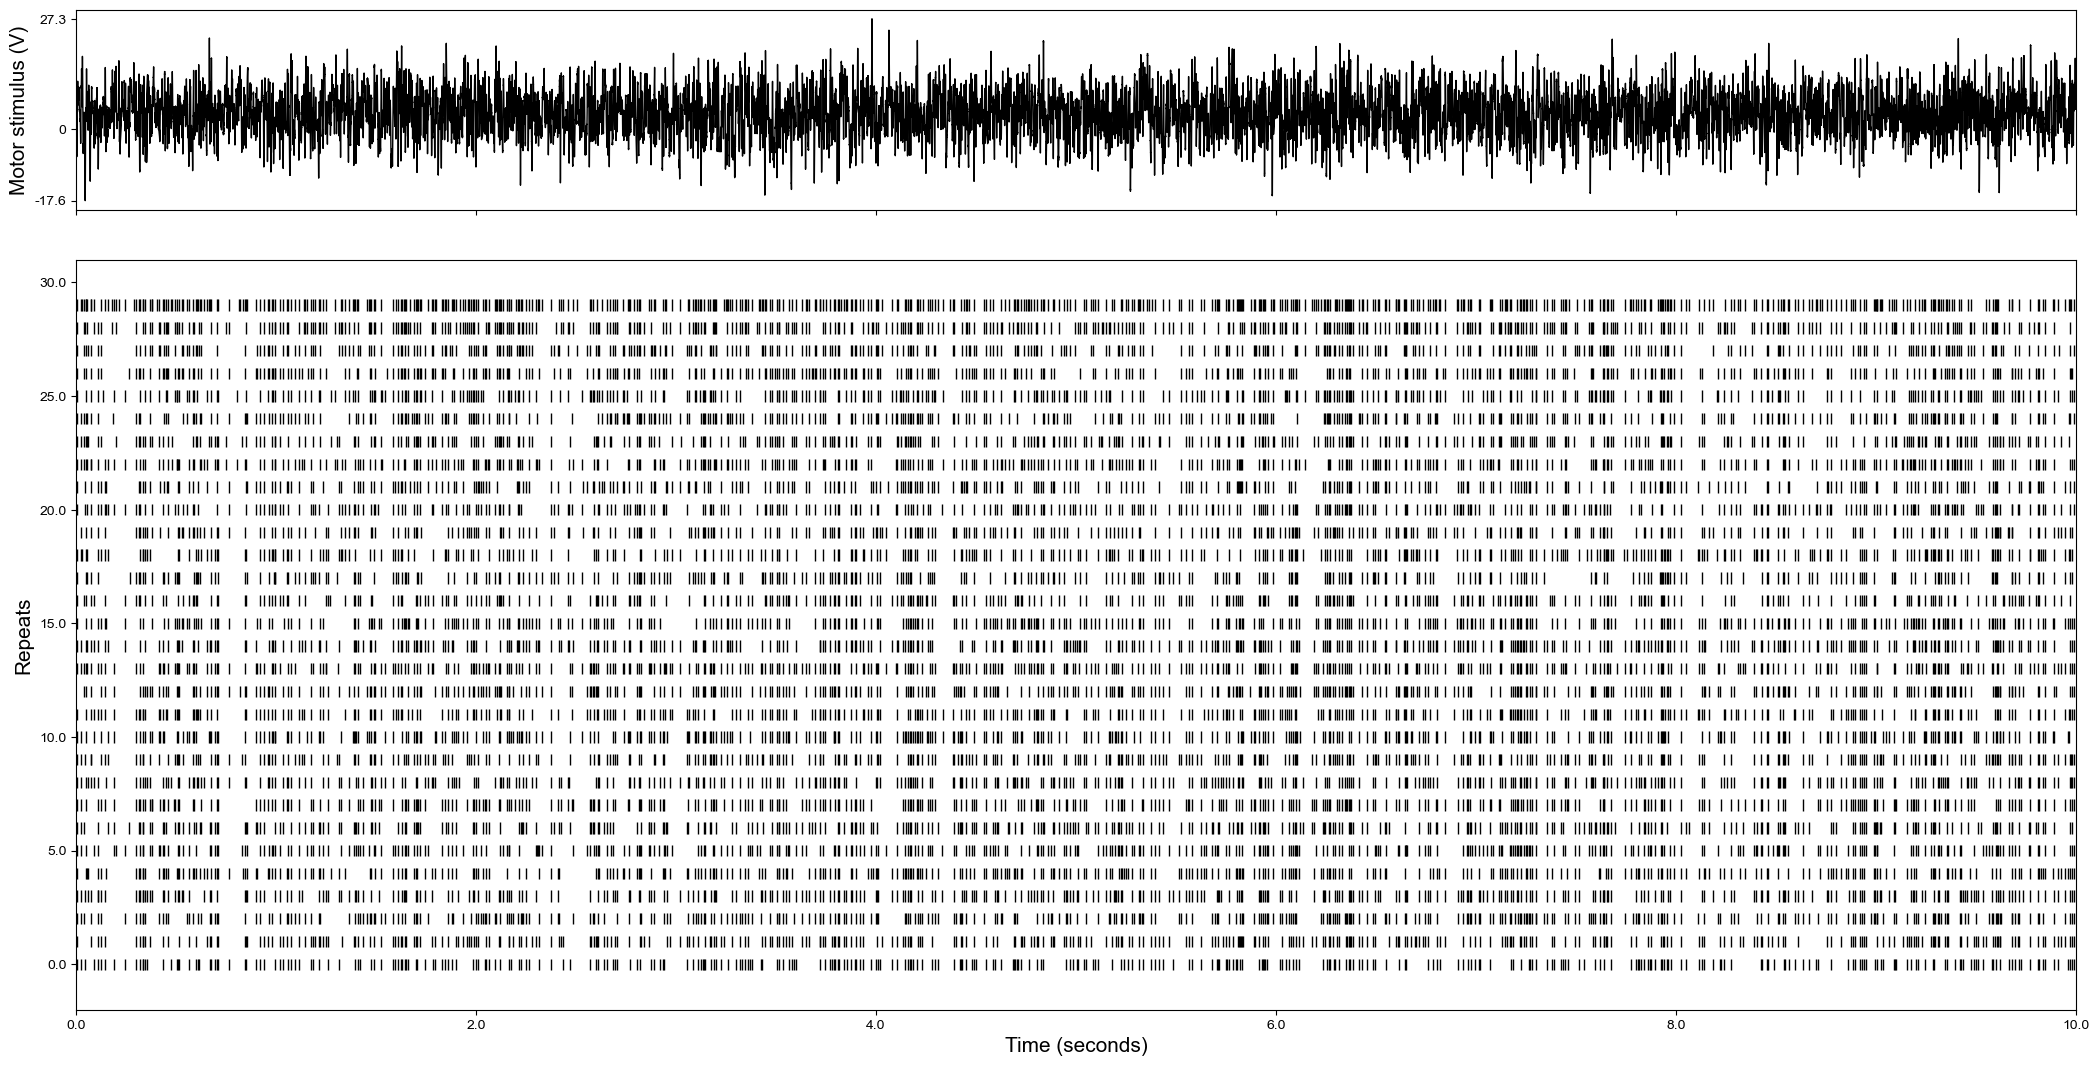

6640


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)


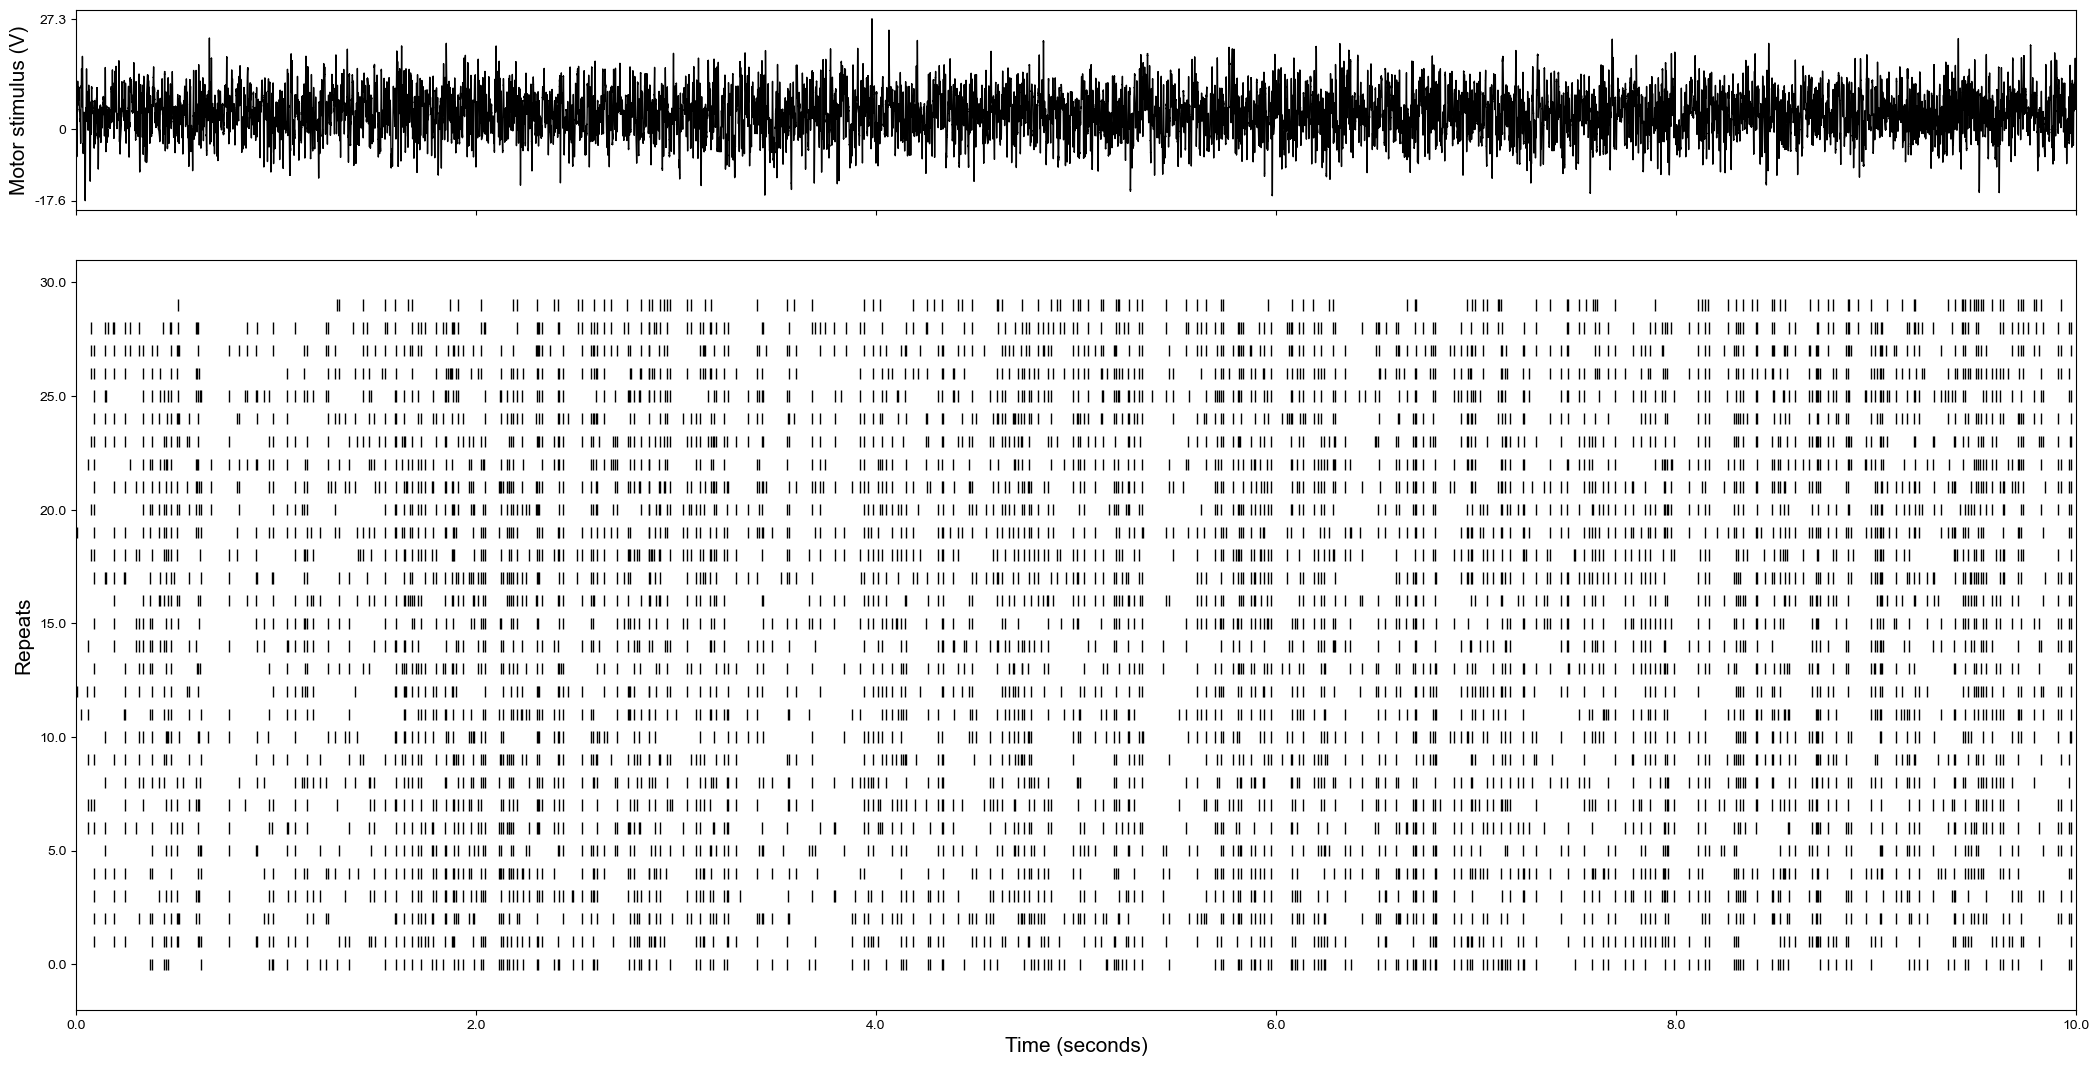

2333


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)


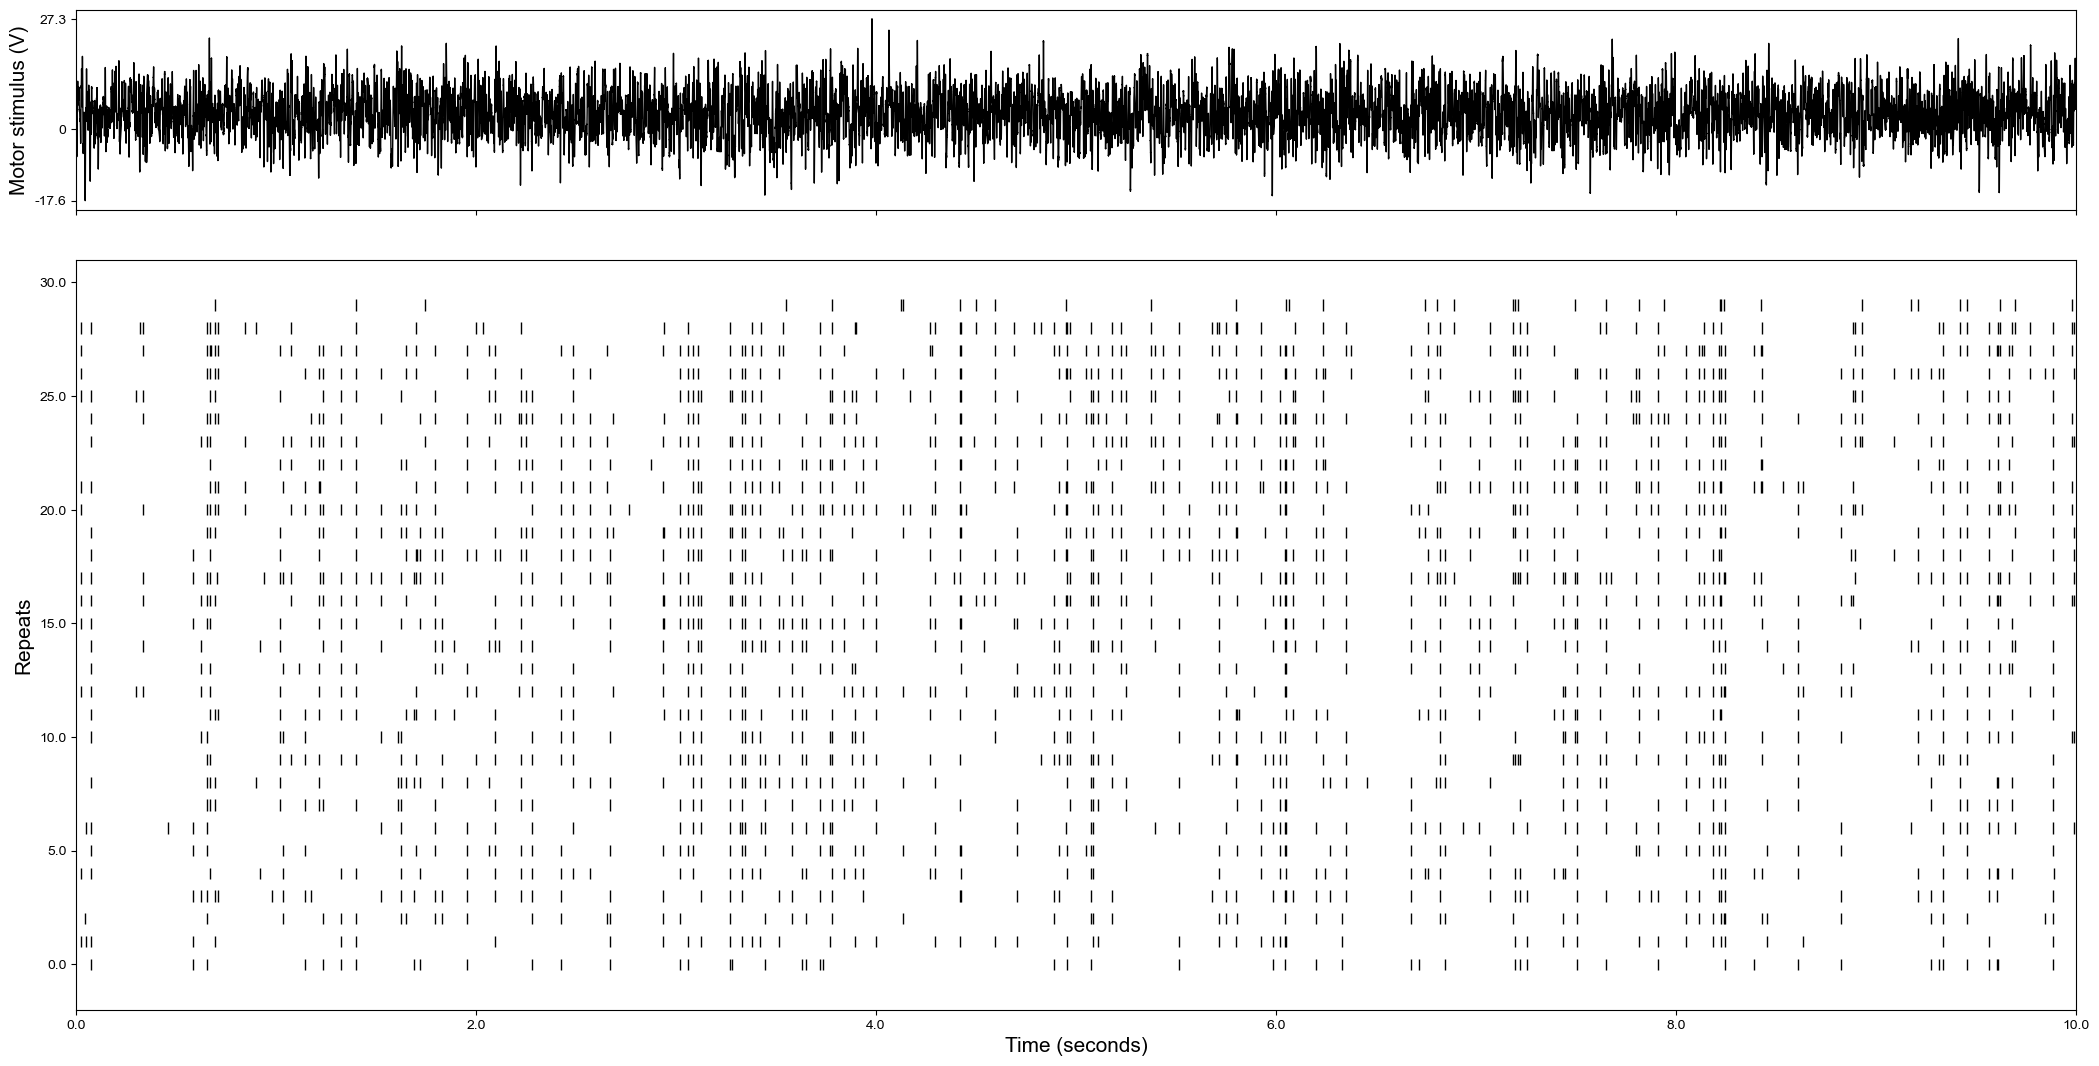

923


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_11752/364730445.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)


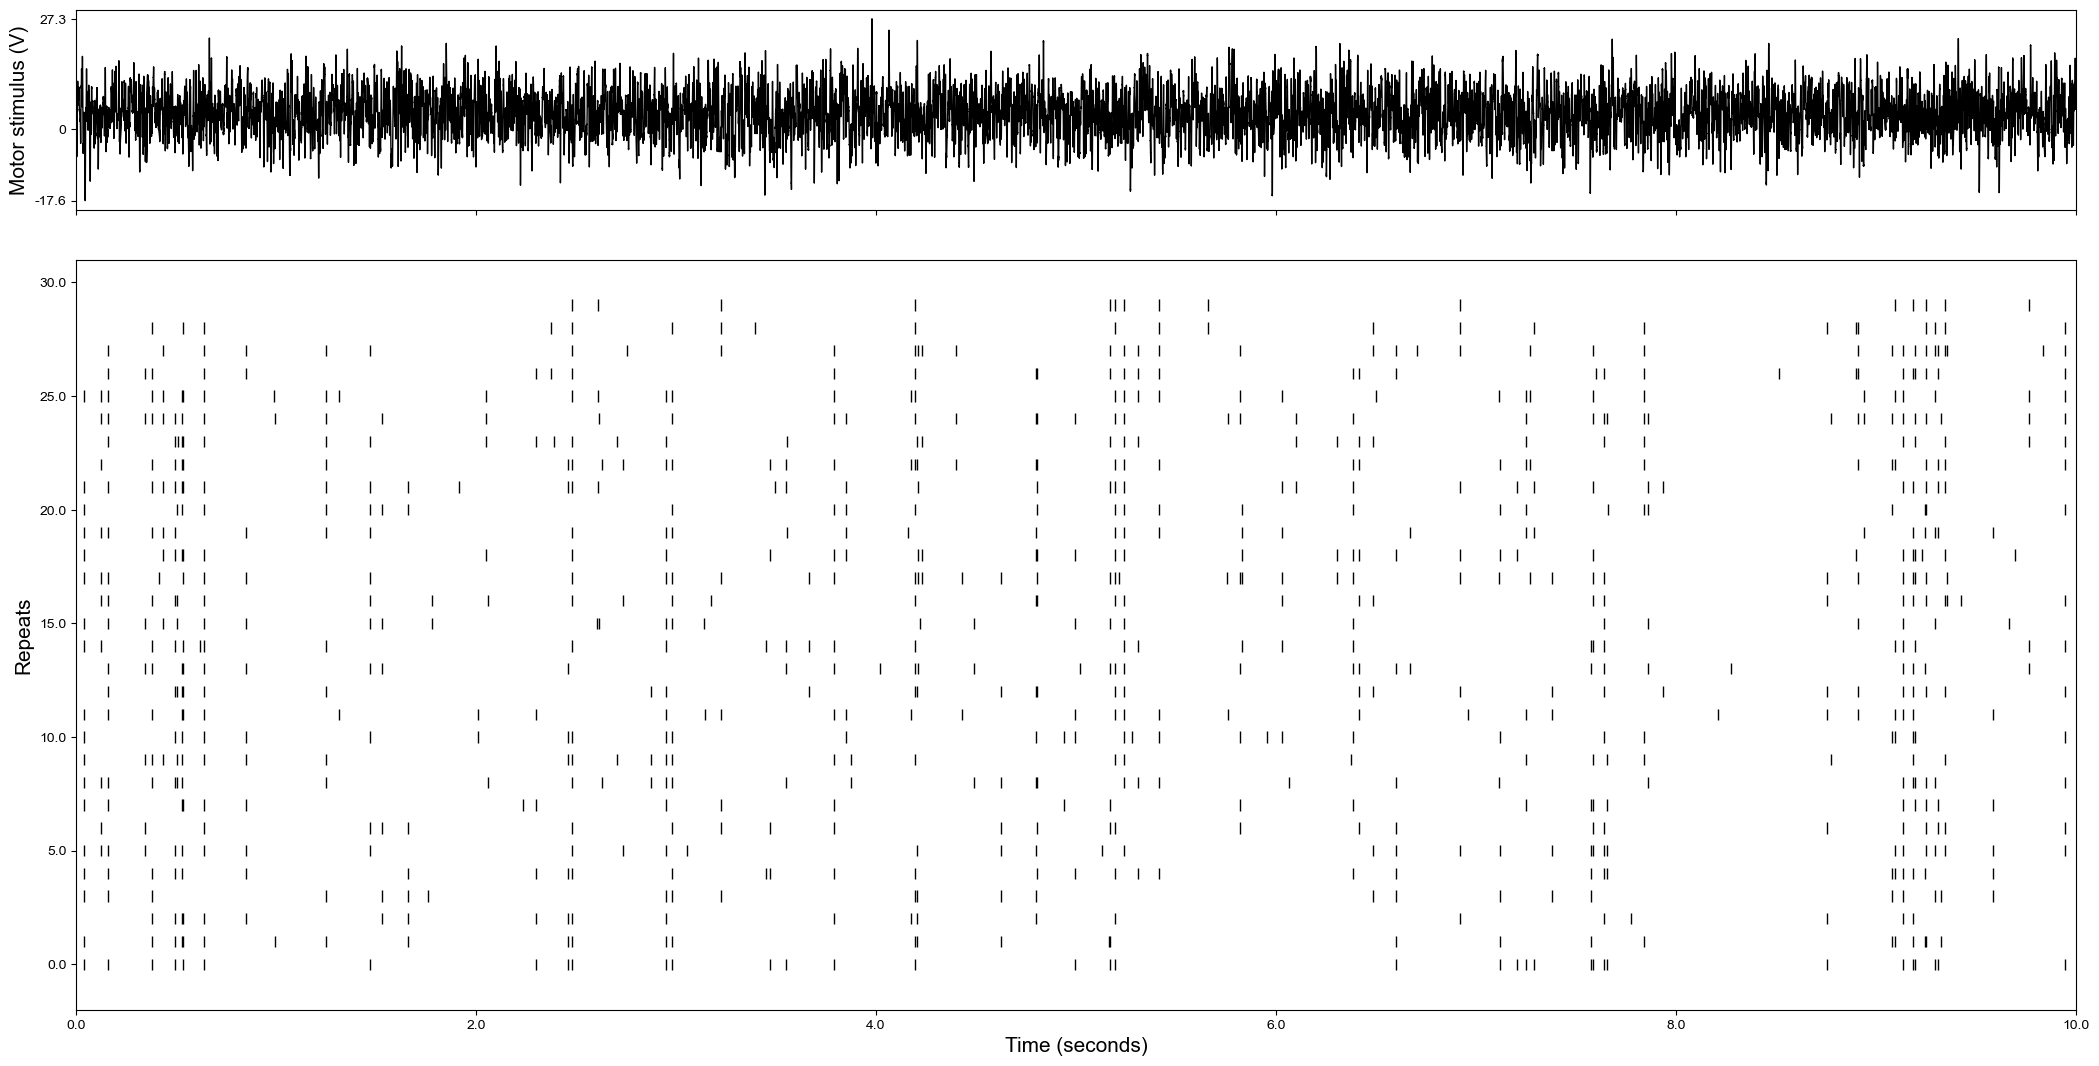

In [9]:
for k in all_Units_aligned.keys():
    f = plt.figure(figsize=(20,10))
    axes = f.add_axes([0.1, 0.8, 1, 0.2])
    axes2 = f.add_axes([0.1, 0, 1, 0.75])
    
    print(len(np.concatenate(all_Units_aligned[k])))
    
    axes.plot(np.arange(0,len(WhiteNoise))*1/Fs, WhiteNoise
              , color = 'black'
              , linewidth = 1
             )
    axes.set_xticklabels([])
    axes.set_ylabel('Motor stimulus (V)', fontsize = 15)
    
    axes2.eventplot(all_Units_aligned[k]
                  ,linelengths = 0.5
                 ,lineoffsets = 1
                 , linewidth = 1
                 , color = 'black'
                   )
    axes2.set_xlim([0, len(WhiteNoise)*1/Fs])
    axes.set_xlim([0, len(WhiteNoise)*1/Fs])
    axes2.set_ylabel('Repeats', fontsize = 15)
    axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
    axes2.set_xlabel('Time (seconds)', fontsize = 15)
    axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)
    stim_min = round(WhiteNoise.min(), 1)
    stim_max = round(WhiteNoise.max(), 1)
    axes.set_yticks([stim_min, 0, stim_max])
    axes.set_yticklabels([stim_min, 0, stim_max], fontsize=10)
    
    raster_data = []
    for repeat_idx, spikes in enumerate(all_Units_aligned[k]):
        for spike_time in np.atleast_1d(np.array(spikes).flatten()):  
            raster_data.append({'repeat': repeat_idx + 1, 'spike_time': spike_time})
    raster_df = pd.DataFrame(raster_data)
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_newraster.csv'
    raster_df.to_csv(filename, index=False)
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_newraster.pdf'
    plt.savefig(filename, bbox_inches='tight')
    plt.show()
    plt.close(f)

In [ ]:
# save aligned spikes and whiteNoise repeat separately 

# whiteNoise_single = pd.DataFrame({'WhiteNoise': WhiteNoise})
# Unit1 = pd.DataFrame({'repeats_unit1': Spike_repeats_unit1})
# Unit2 = pd.DataFrame({'repeats_unit2': Spike_repeats_unit2})

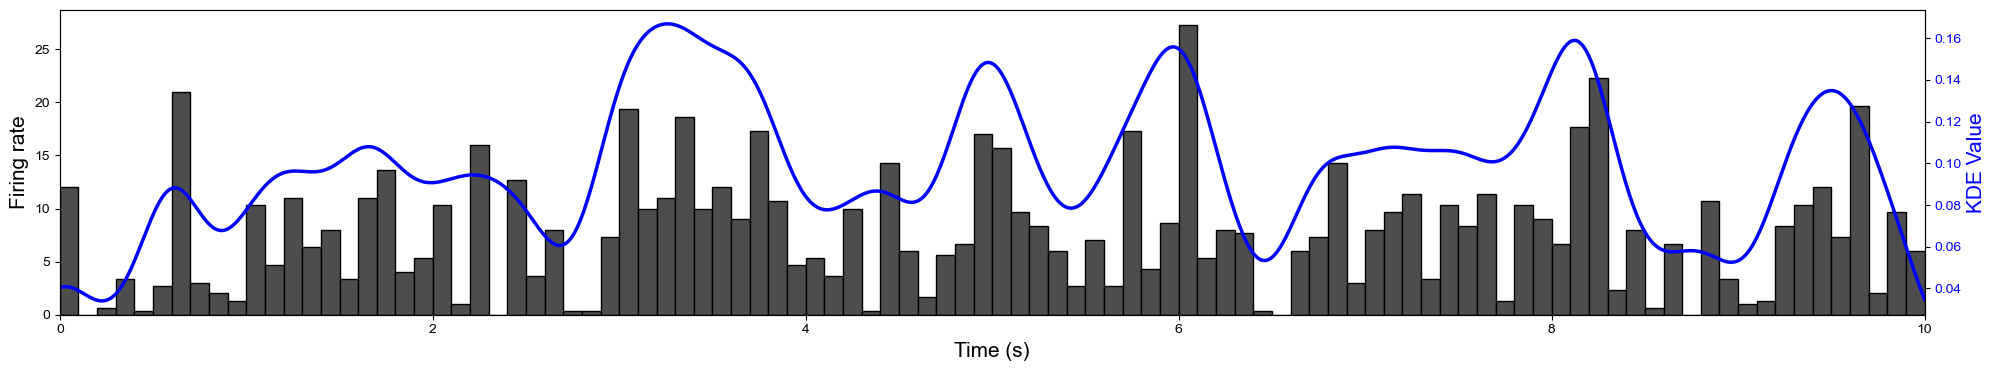

In [10]:
#create the PSTH aligning to the raster plot here 
moth_name = "m31_wn2"
unit_name = "unit_2"

bin_size = 0.1 
stim_duration = 10.0 #duration of one repeat

raster = all_Units_aligned[unit_name] # extract all the spike and unit data from the raster
num_repeats = len(raster) 
spikes = np.concatenate(raster)
edges = np.arange(0, stim_duration + bin_size, bin_size)
counts, _ = np.histogram(spikes, bins=edges)
psth = counts / (num_repeats * bin_size) #takes the count which is total no. of spikes and converts to firing rate (spikes/second)

#plot the PSTH with Gaussian KDE on the same axis 
fig, ax1 = plt.subplots(figsize=(20, 3.75))
ax2 = ax1.twinx()

ax1.bar(
    edges[:-1],
    psth,
    width=bin_size,
    align="edge",
    edgecolor="black",
    color="0.3")

kde = gaussian_kde(edges[:-1], weights=psth, bw_method=0.06)
x_grid = np.linspace(edges[:-1].min(), edges[-1].max(), 1000)
density = kde(x_grid)
ax2.plot(x_grid, density, color="blue", linewidth=2.5)

ax1.set_xlim(0, stim_duration)
ax1.set_xlabel("Time (s)", fontsize=15)
ax1.set_ylabel("Firing rate", fontsize=15)
ax1.tick_params(axis='both', labelsize=10)

ax2.set_ylabel("KDE Value", fontsize=15, color="blue")
ax2.tick_params(axis='y', labelsize=10, labelcolor="blue")

plt.tight_layout()

save_path = ("/Users/meghnaanand/Desktop/Analysis/"+ moth_name + "_" + unit_name + "_PSTH.pdf")
plt.savefig(save_path, bbox_inches="tight")
plt.show()

full_data_df = pd.DataFrame({
    'time': x_grid,
    'kde': density})
save_path = (f"/Users/meghnaanand/Desktop/Analysis/"f"{moth_name}_{unit_name}_fullgaussiankde.csv")
full_data_df.to_csv(save_path, index=False)

kde_at_bins = kde(edges[:-1]) #matches the kde values aligning bin values as opposed to all points for comparison
full_data_df = pd.DataFrame({
    'time': edges[:-1],
    'psth': psth,
    'kde': kde_at_bins})
save_path = (f"/Users/meghnaanand/Desktop/Analysis/"f"{moth_name}_{unit_name}_PSTH_data.csv")
full_data_df.to_csv(save_path, index=False)



 



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import pickle
import matplotlib

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'
# ── EDIT THESE ──────────────────────────────────────────────
moth_name = "m31_wn2"
unit_name = "unit_2"
bin_size = 0.1
stim_duration = 10.0

# File paths
data_dir = "/Users/meghnaanand/Desktop/Analysis"
pred_dir = "/Users/meghnaanand/Desktop/Prediction"
pickle_file = f"{data_dir}/{moth_name}_timeStamps.pickle"

# Remove underscore for prediction file path
unit_name_file = unit_name.replace("_", "")  # "unit_2" → "unit2"
predicted_kde_file = f"{pred_dir}/{moth_name}_{unit_name_file}/{moth_name}_{unit_name_file}_predictedgaussiankde.csv"
# ─────────────────────────────────────────────────────────────

# Load spike data
with open(pickle_file, "rb") as f:
    testout = pickle.load(f)
all_Units_aligned = testout[0]
raster = all_Units_aligned[unit_name]

# Compute PSTH
num_repeats = len(raster)
spikes = np.concatenate(raster)
edges = np.arange(0, stim_duration + bin_size, bin_size)
counts, _ = np.histogram(spikes, bins=edges)
psth = counts / (num_repeats * bin_size)

# Compute observed KDE
kde = gaussian_kde(edges[:-1], weights=psth, bw_method=0.06)
x_grid = np.linspace(edges[:-1].min(), edges[-1].max(), 1000)
density_observed = kde(x_grid)

# Load predicted KDE
predicted_kde = pd.read_csv(predicted_kde_file)

# Plot PSTH with both observed and predicted KDE
fig, ax1 = plt.subplots(figsize=(20, 3.75))
ax2 = ax1.twinx()

# PSTH bars
ax1.bar(edges[:-1], psth, width=bin_size, align="edge", 
        edgecolor="black", color="0.3", label="PSTH")

# Observed KDE (solid blue)
ax2.plot(x_grid, density_observed, color="blue", linewidth=2.5, 
         label="Observed KDE")

# Predicted KDE (dotted red)
ax2.plot(predicted_kde['time'], predicted_kde['kde'], color="red", 
         linewidth=2.5, linestyle="--", label="Predicted KDE")

# Formatting
ax1.set_xlim(0, stim_duration)
ax1.set_xlabel("Time (s)", fontsize=15)
ax1.set_ylabel("Firing rate (Hz)", fontsize=15)
ax1.tick_params(axis='both', labelsize=10)
ax2.set_ylabel("KDE Value", fontsize=15)
ax2.tick_params(axis='y', labelsize=10)

# Add legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, fontsize=12, loc='upper right')

plt.tight_layout()

# Save
save_path = f"{data_dir}/{moth_name}_{unit_name}_PSTH_with_prediction.pdf"
plt.savefig(save_path, bbox_inches="tight")
print(f"✓ Saved: {save_path}")

plt.show()

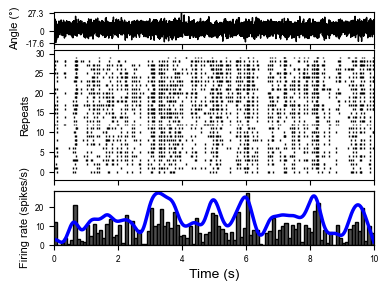

Saved m31_wn2 unit_2


In [13]:
moth_name = "m31_wn2"
unit_name = "unit_2"
bin_size      = 0.1
stim_duration = 10.0

with open(f"/Users/meghnaanand/Desktop/Analysis/{moth_name}_angletimeStamps.pickle", "rb") as f:
    testout = pickle.load(f)
all_Units_aligned = testout[0]

WhiteNoise = np.array(testout[2])
t_stim = np.arange(len(WhiteNoise)) / Fs

# then in the plot use matching lengths
n_samples = int(stim_duration * Fs)

# get raster data
raster     = all_Units_aligned[unit_name]
num_repeats = len(raster)
spikes_all  = np.concatenate(raster)

# compute PSTH
edges      = np.arange(0, stim_duration + bin_size, bin_size)
counts, _  = np.histogram(spikes_all, bins=edges)
psth       = counts / (num_repeats * bin_size)

# KDE
kde        = gaussian_kde(edges[:-1], weights=psth, bw_method=0.06)
x_grid     = np.linspace(edges[:-1].min(), edges[-1].max(), 1000)
density    = kde(x_grid)

# ── Figure — 3 panels sharing x axis ──
fig = plt.figure(figsize=(3.76, 2.71))
ax_stim = fig.add_axes([0.1, 0.82, 0.85, 0.12])  # stimulus
ax_rast = fig.add_axes([0.1, 0.32, 0.85, 0.48])  # raster
ax_psth = fig.add_axes([0.1, 0.08, 0.85, 0.20])  # PSTH

# ── Stimulus ──
ax_stim.plot(t_stim[:n_samples],
             WhiteNoise[:n_samples],
             color='black', lw=1)
ax_stim.set_xlim(0, stim_duration)
ax_stim.set_ylabel('Angle (°)', fontsize=8)
ax_stim.set_xticklabels([])
ax_stim.tick_params(axis='y', labelsize=6)
stim_min = round(WhiteNoise[:n_samples].min(), 1)
stim_max = round(WhiteNoise[:n_samples].max(), 1)
ax_stim.set_yticks([stim_min, 0, stim_max])
ax_stim.set_yticklabels([stim_min, 0, stim_max], fontsize=6)

# ── Raster ──
ax_rast.eventplot(raster, linelengths=0.5, lineoffsets=1,
                  linewidth=1, colors='black')
ax_rast.set_xlim(0, stim_duration)
ax_rast.set_ylabel('Repeats', fontsize=8)
ax_rast.set_xticklabels([])
ax_rast.tick_params(axis='both', labelsize=6)

# ── PSTH ──
ax_psth2 = ax_psth.twinx()
ax_psth.bar(edges[:-1], psth, width=bin_size, align='edge',
            edgecolor='black', color='0.3')
ax_psth2.plot(x_grid, density, color='blue', linewidth=2.5)
ax_psth.set_xlim(0, stim_duration)
ax_psth.set_xlabel('Time (s)', fontsize=10)
ax_psth.set_ylabel('Firing rate (spikes/s)', fontsize=8)
ax_psth.tick_params(axis='both', labelsize=6)
ax_psth2.set_yticks([])
ax_psth2.set_ylabel('')

plt.savefig(f"/Users/meghnaanand/Desktop/Analysis/{moth_name}_{unit_name}_angleRasterPSTH.pdf",
            bbox_inches='tight')
plt.show()
plt.close(fig)
print(f"Saved {moth_name} {unit_name}")

In [14]:
print (3e8 - 6e5)

299400000.0
